# hpc_perf2: performance and diagnostics across sample sizes

Analyse the archived effective config, timed trials and diagnostics for
**1000 Genomes Project, chr20p**. AF cutoffs are 0.01 and 0.1; the requested minimum is
150 kb, converted separately to a genome-wide mean inference-site count for
each cohort. The figures label AF with the corresponding nominal AC rounded
from 2n × AF. Multi-cohort legends list ACs in increasing sample-size order.

Each setting has **one trial**, with 32 matching workers. Lines connect
observations; they do not estimate replicate uncertainty. Full HMM supplies
one shared baseline per cohort. All comparisons begin at prepared ancestor
references and include loading, setup, matching and output. Resident timings
and stage breakdowns were not collected. No ARG metrics are calculated.

Outputs, dates, matched mutation tables and figures are cached beside the
archive contents under `for_plots/`. This notebook uses only archived data.

In [1]:
import logging
import pathlib

import IPython.display as ipython_display
import pandas as pd

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)

/Users/duncan/work/dphil-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
repository_dir = pathlib.Path.cwd()
config_path = {
    "cache_subdir": "for_plots",
    "workers": None,
    "helper_threads": 1,
    "dating": {
        "post_process": {"split_ultimate": True, "erase_flanks": True},
        "preprocess": {"delete_intervals": [], "split_disjoint": True},
        "estimation": {
            "method": "variational_gamma",
            "time_units": "generations",
            "set_metadata": True,
            "progress": False,
            "singletons_phased": True,
        },
    },
    "frequency_bins": {
        "cutoffs": [0.01, 0.5],
        "labels": ["DAF < 0.01", "0.01 ≤ DAF < 0.5", "DAF ≥ 0.5"],
    },
    "title": "hpc_perf2",
    "description": "1000 Genomes Project · chr20p",
    "data_dir": repository_dir / "data/ch5/hpc_perf2_diagnostics",
    "mutation_rate": 1.29e-08,
    "population_groups": {
        "African": ["AFR"],
        "Non-African": ["EUR", "EAS", "SAS", "AMR"],
    },
}
config_path["base_dir"] = repository_dir
config = nb_utils.paramsearch_load_config(config_path)
plot_data = nb_utils.prepare_scaling_data(config)
logging.basicConfig(level=logging.INFO, format="%(message)s")

## Archived run checks

Sample counts come from saved cohort identities. Saved quality checks verify
called alleles and sample/reference metadata; they do not establish genealogy
accuracy. The resolved site-count minimum is included below. Diagnostic
coverage uses the observed inference-site extent, excluding chromosome flanks.

In [3]:
if __name__ == "__main__":
    cohorts = nb_utils.cohort_table(config)
    performance = nb_utils.performance_runs(config)
    summary = nb_utils.diagnostic_summary(config)
    ipython_display.display(cohorts)
    columns = [
        "num_samples",
        "method",
        "af_cutoff",
        "wall_s",
        "wall_ms_per_haplotype",
        "speedup",
        "cpu_s",
        "effective_cores",
        "trial_peak_private_gib",
    ]
    ipython_display.display(performance[columns].round(3))

,dataset,num_samples,num_haplotypes,num_sites,analysis_span_mb,has_truth,min_region_size_kb,min_focal_region_size
0,tgp_chr20p_n320,320,640,222876,26.047224,False,150,1283
1,tgp_chr20p_n1012,1012,2024,342008,26.047226,False,150,1970
2,tgp_chr20p_n3202,3202,6404,580909,26.047226,False,150,3345


,num_samples,method,af_cutoff,wall_s,wall_ms_per_haplotype,speedup,cpu_s,effective_cores,trial_peak_private_gib
0,320,full_hmm,NaN,72.748,113.669,1.000,434.329,5.970,53.252
2,320,greedy,0.01,40.112,62.675,1.814,158.261,3.945,10.535
1,320,greedy,0.10,39.184,61.225,1.857,125.684,3.208,10.608
5,1012,full_hmm,NaN,114.070,56.359,1.000,1803.361,15.809,79.227
4,1012,greedy,0.01,71.787,35.468,1.589,707.391,9.854,15.530
3,1012,greedy,0.10,67.900,33.547,1.680,495.796,7.302,15.599
8,3202,full_hmm,NaN,441.302,68.910,1.000,12212.969,27.675,131.695
7,3202,greedy,0.01,235.416,36.761,1.875,4712.562,20.018,26.613
6,3202,greedy,0.10,191.494,29.902,2.305,3170.572,16.557,26.662


## Performance against sample size

Wall time is the measured end-to-end window. Throughput divides that wall
time by the number of matched haplotypes at fixed worker count. Private memory
is sampled **sum of process-tree USS**, not RSS; shared mappings are not
multiplied by the number of workers. The whole-trial peak includes setup and
output. Average cores = (user + system CPU seconds) / measured wall seconds.
Speedup = Full HMM wall time / method wall time within the same cohort.
The sample-size axis is logarithmic; every measured size is labelled.

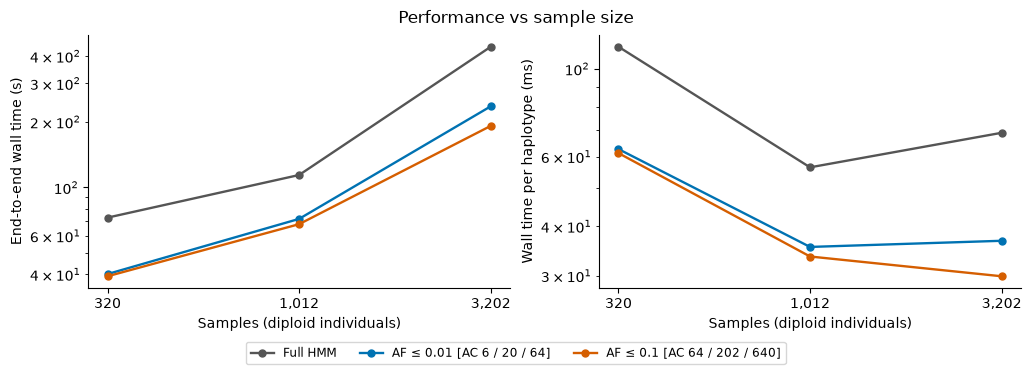

In [4]:
if __name__ == "__main__":
    metrics = {
        "wall_s": "End-to-end wall time (s)",
        "wall_ms_per_haplotype": "Wall time per haplotype (ms)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Performance vs sample size",
            include_full=True,
            log_y=True,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "performance_wall_throughput",
        export_dpi=180,
    )

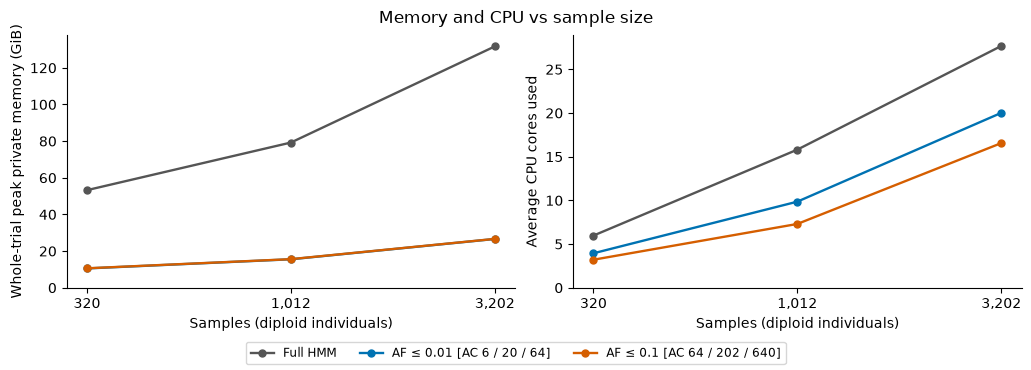

In [5]:
if __name__ == "__main__":
    metrics = {
        "trial_peak_private_gib": "Whole-trial peak private memory (GiB)",
        "effective_cores": "Average CPU cores used",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Memory and CPU vs sample size",
            include_full=True,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "performance_memory_cpu",
        export_dpi=180,
    )

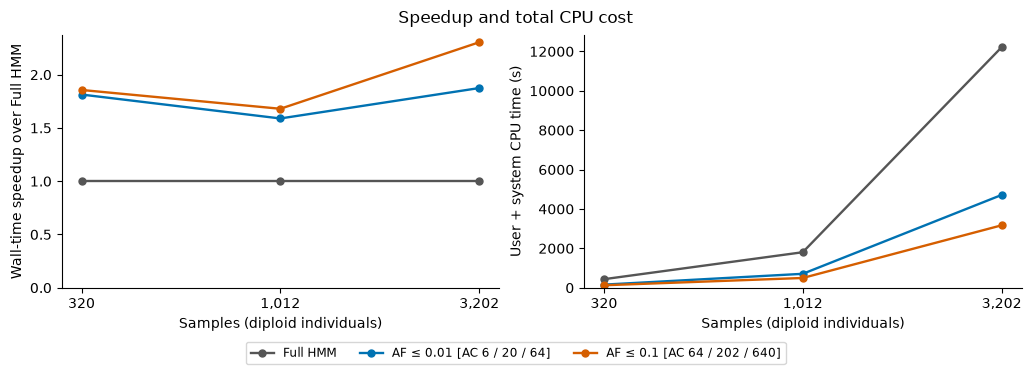

In [6]:
if __name__ == "__main__":
    metrics = {
        "speedup": "Wall-time speedup over Full HMM",
        "cpu_s": "User + system CPU time (s)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Speedup and total CPU cost",
            include_full=True,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "performance_speedup_cpu_cost",
        export_dpi=180,
    )

## Recorded workload

Focal site coverage uses the timed runner's summed focal/domain site counts,
rather than physical spans. Gap calls count separate HMM invocations. These
are workload measures, not timing decompositions.

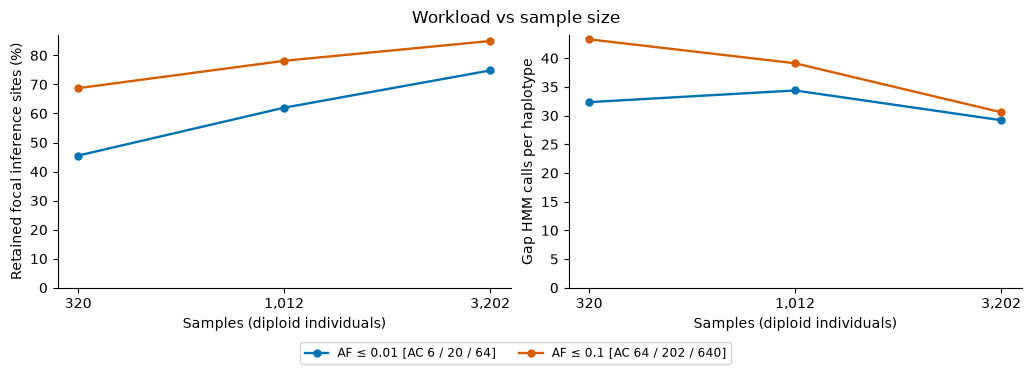

In [7]:
if __name__ == "__main__":
    metrics = {
        "focal_site_coverage_percentage": "Retained focal inference sites (%)",
        "gap_calls_per_haplotype": "Gap HMM calls per haplotype",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Workload vs sample size",
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "workload_scaling",
        export_dpi=180,
    )

## Extra switches and parent agreement

Each diagnostic mean weights haplotypes equally. Error bars are one
haplotype SEM within a cohort; paired haplotypes are dependent and these are
not simulation or benchmark replicate errors. Percentage switch increases
are calculated per haplotype before averaging. Parent agreement denominators
are evaluated inference sites in focal regions or gaps. Its y axes cover the
displayed means and SEMs rather than starting at zero.

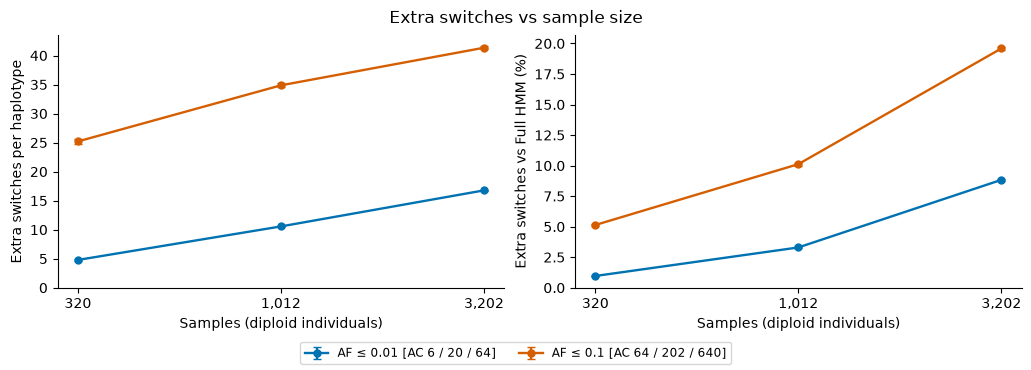

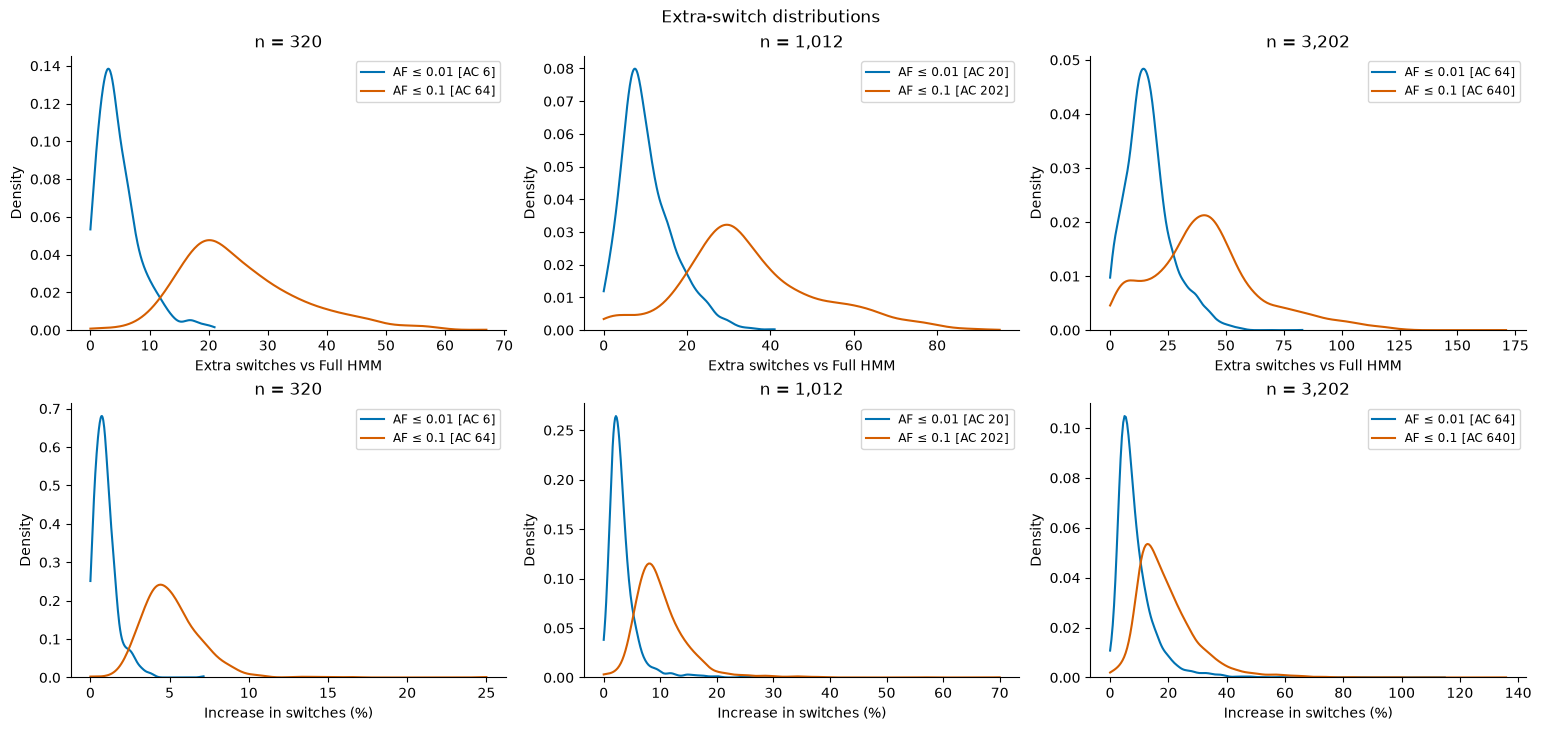

In [8]:
if __name__ == "__main__":
    metrics = {
        "num_extra_switches_mean": "Extra switches per haplotype",
        "switch_increase_percentage_mean": "Extra switches vs Full HMM (%)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            summary,
            metrics,
            "Extra switches vs sample size",
            sem=True,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "extra_switches_scaling",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_extra_switch_distributions(
            plot_data,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            kde_grid_size=256,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
        ),
        "extra_switch_distributions",
        export_dpi=180,
    )

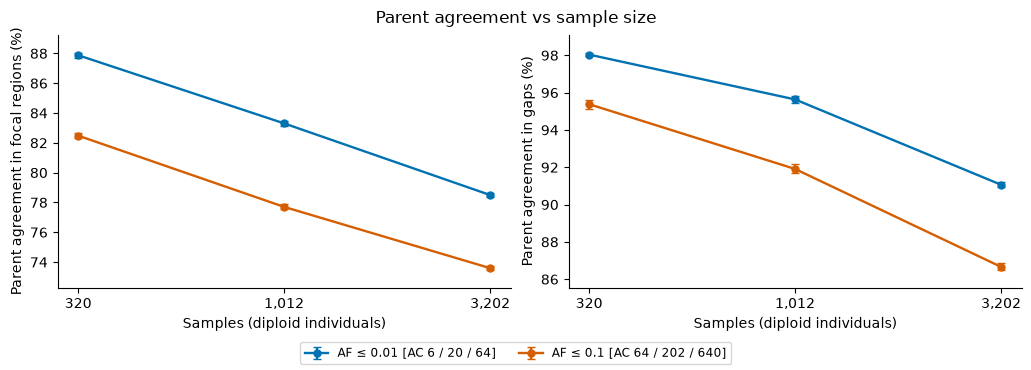

In [9]:
if __name__ == "__main__":
    metrics = {
        "focal_agreement_percentage_mean": "Parent agreement in focal regions (%)",
        "gap_agreement_percentage_mean": "Parent agreement in gaps (%)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            summary,
            metrics,
            "Parent agreement vs sample size",
            sem=True,
            zoom=True,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "parent_agreement_scaling",
        export_dpi=180,
    )

## Physical focal coverage and region lengths

Population groups follow the scientific settings in this notebook. Curves show physical coverage
over the archived analysis extent, with one haplotype SEM. Histograms show
**retained** connected focal regions at 150 kb; unfiltered regions were not
archived. `num_bins` is directly editable below. Dashed site thresholds are
the actual filters. The 150-kb marker in the physical plot is a mean-density
equivalent, not a strict physical cutoff for each region.

Reflected Scott KDEs use every interval, including tails outside the displayed
pooled 99th percentile. Legends report the omitted tail fraction. Site and
physical lengths are cached as lossless frequency tables. Gap plots use
density curves and dashed median markers, with no histogram or coverage plot.

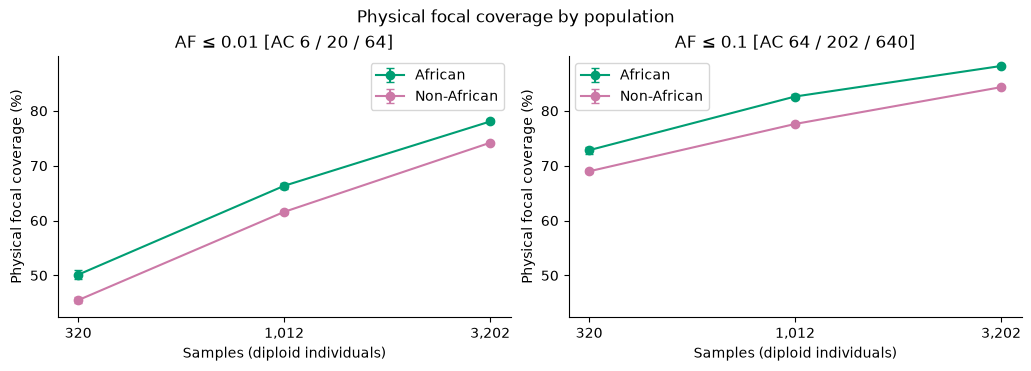

In [10]:
if __name__ == "__main__":
    population_coverage = nb_utils.population_coverage(config)
    lengths = nb_utils.perf_scaling_length_counts(config)
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_coverage(
            plot_data,
            population_coverage,
            cohort_labels={},
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=5.1,
            population_colors={"African": "#009E73", "Non-African": "#CC79A7"},
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "focal_population_coverage",
        export_dpi=180,
    )

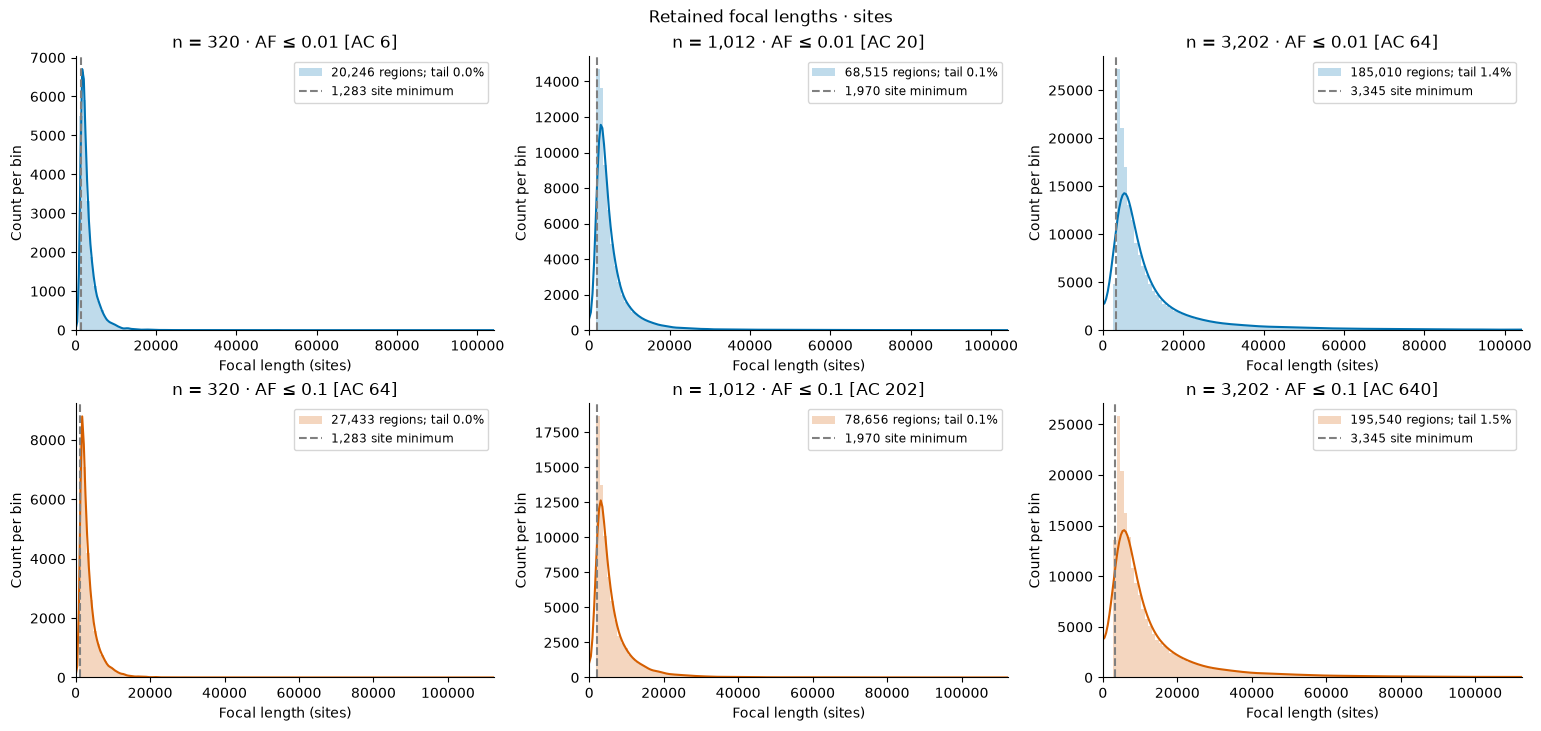

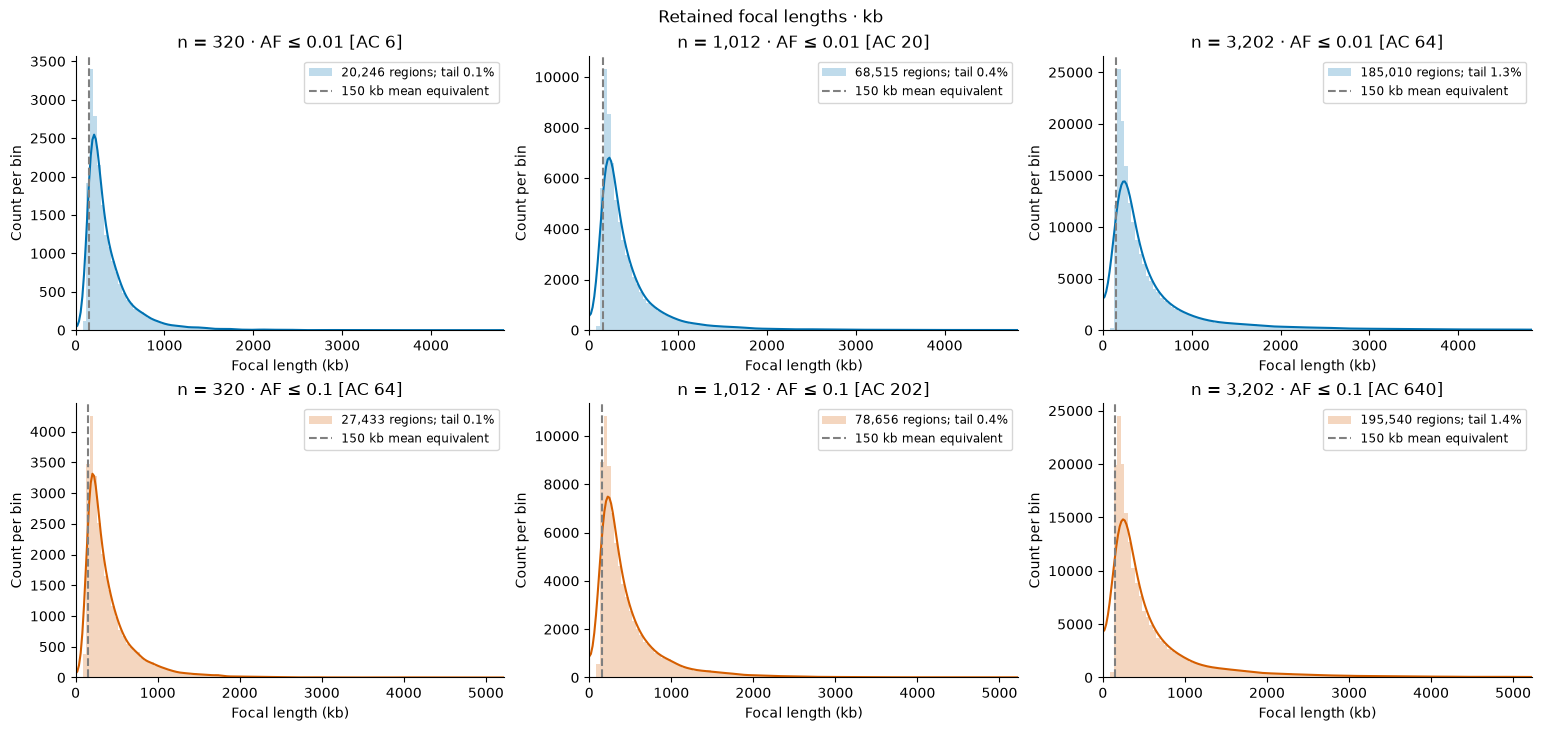

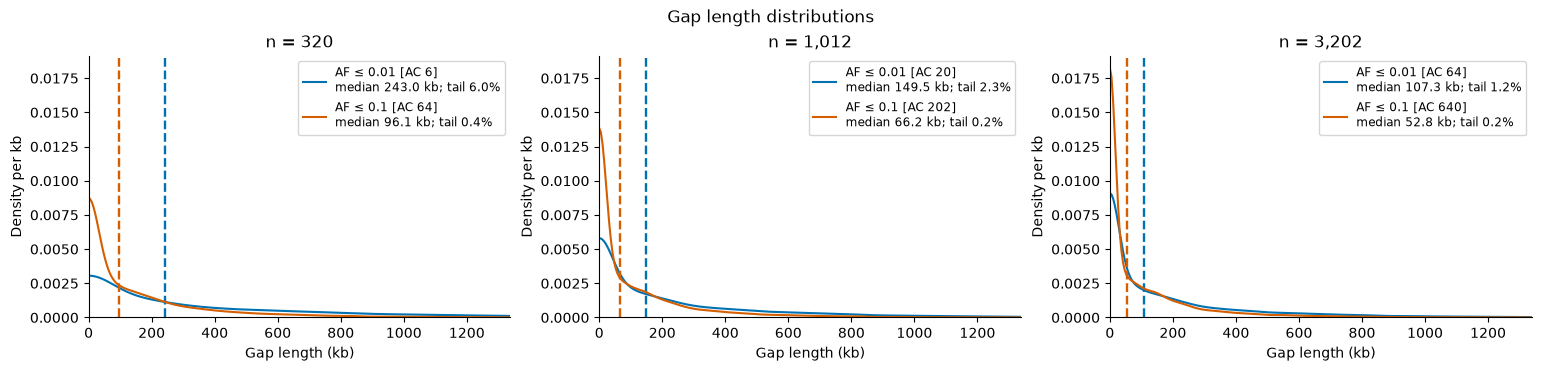

In [11]:
if __name__ == "__main__":
    num_bins = 120
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_focal_lengths(
            plot_data,
            lengths,
            unit="sites",
            num_bins=num_bins,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            histogram_alpha=0.25,
            kde_grid_size=256,
            length_display_quantile=0.99,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=5.1,
        ),
        "focal_lengths_sites",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_focal_lengths(
            plot_data,
            lengths,
            unit="kb",
            num_bins=num_bins,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            histogram_alpha=0.25,
            kde_grid_size=256,
            length_display_quantile=0.99,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=5.1,
        ),
        "focal_lengths_kb",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_gap_lengths(
            plot_data,
            lengths,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            kde_grid_size=256,
            length_display_quantile=0.99,
            line_width=1.7,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=5.1,
        ),
        "gap_lengths_kb",
        export_dpi=180,
    )

### One-site gaps

Bars count gap regions containing exactly one inference site, pooled across
all haplotypes. Labels show their percentage of **all gap regions** for that
dataset and AF cutoff, including the full length-distribution tails. Each
sample size has a column; each AF cutoff has a bar at the fixed kb minimum.

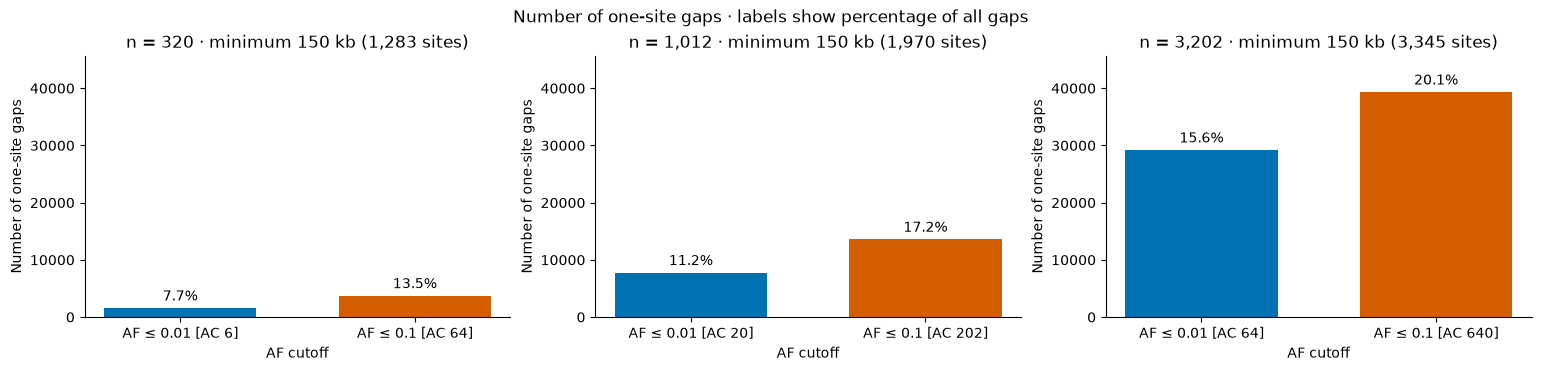

In [4]:
if __name__ == "__main__":
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_one_site_gaps(
            plot_data,
            lengths,
            bar_width=0.65,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=5.1,
            range_margin=0.08,
        ),
        "one_site_gaps",
        export_dpi=180,
    )

## Switch composition

Switches partition into within-focal, within-gap and seam categories. For
each AF and cohort, Full HMM is partitioned with that same focal mask; its
total does not change with the mask. All columns display their y-axis ticks.

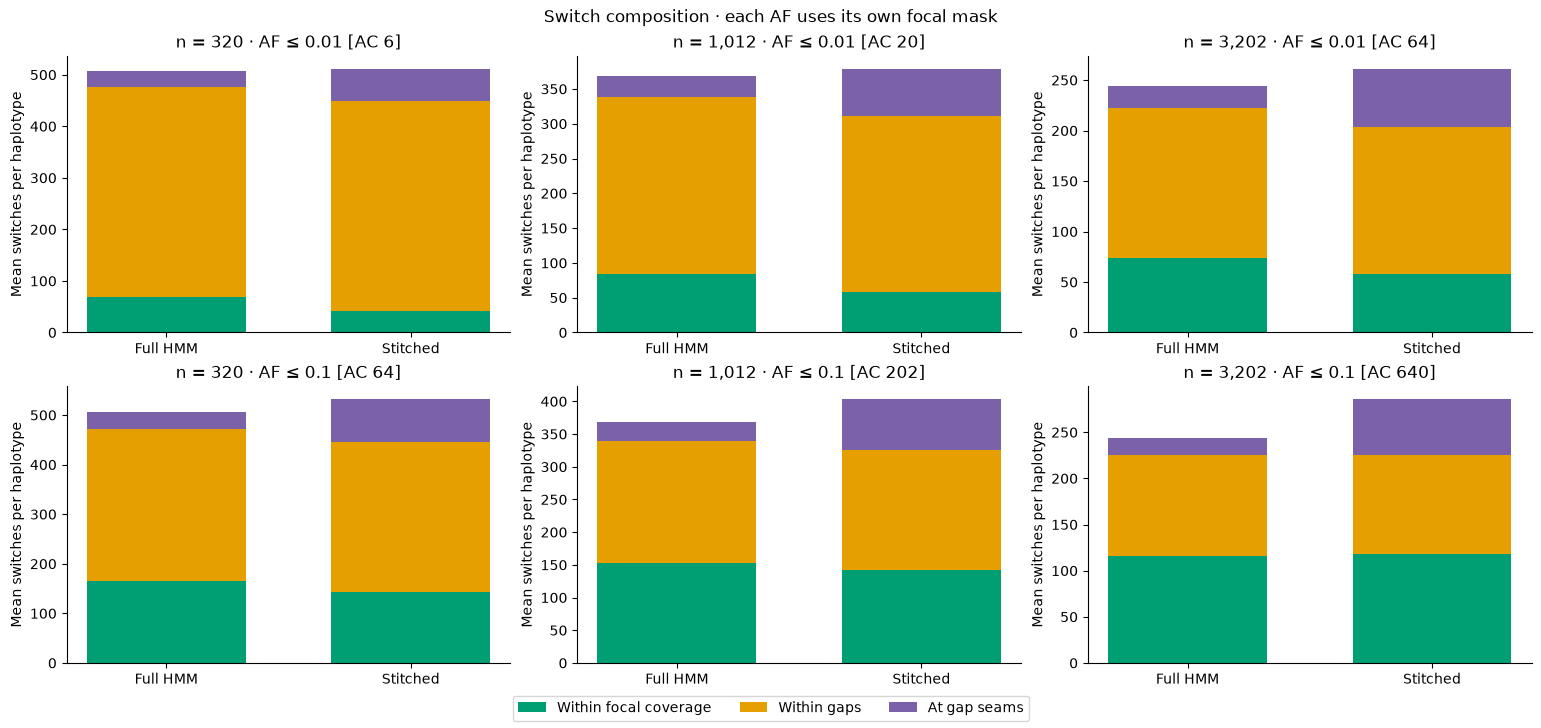

In [12]:
if __name__ == "__main__":
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_switch_composition(
            plot_data,
            summary,
            bar_width=0.65,
            cohort_labels={},
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            switch_categories=["focal", "gap", "seam"],
            switch_colors=["#009E73", "#E69F00", "#7B61A8"],
            switch_labels=["Within focal coverage", "Within gaps", "At gap seams"],
        ),
        "switch_composition",
        export_dpi=180,
    )

## Which ancestors supply the gap copying paths?

This diagnoses Gil's 15 October proposal to restrict gap HMM matching to an
older reference. It examines the existing paths, without rerunning matching.
For each AF cutoff, Full HMM and stitched paths use the **same stitched gap
mask**. All categories are specific to the sample haplotype:

- **Older:** reference node time is strictly greater than the AF cutoff.
- **Recent, not focal:** node time is at or below the cutoff, but the sample
  does not carry that ancestor's selected focal seed.
- **Focal candidate:** node time is at or below the cutoff and the sample
  carries its selected seed, even if no retained greedy region used it.
  The seed can lie outside the particular gap being measured.

These are tsinfer's frequency-based ancestor times, not dates in generations.
The two artificial old roots belong to the older category. Every archived
reference has one mutation per inference site; these identify the original
focal sites. Recover the configured leftmost seed per ancestor and check that
the recent-node counts match the benchmark's eligible-ancestor counts.

Carrier status is reconstructed from the saved **Full HMM** haplotypes and
held fixed for both methods, including terminal sample-mutation overrides.
These are the saved alleles; original missing-call flags are not archived.
No genotype stores are opened. Blue would be retained by an older-only HMM;
orange and green show existing matches that such a restriction would exclude.
This does not predict which replacement parents the restricted HMM would use.

The first plot partitions gap base pairs. The second counts distinct parents
once per haplotype across all its gaps. Percentages are calculated within each
haplotype, then averaged; haplotypes with an empty denominator are omitted.
Site-weighted and copying-segment-weighted percentages are also cached.

Gap-parent composition: tgp_chr20p_n1012


Gap-parent composition: tgp_chr20p_n3202


Gap-parent composition: tgp_chr20p_n320


,num_samples,method,af_cutoff,category,span_bp_percentage_mean,distinct_parents_percentage_mean
0,1012,full_hmm,0.01,focal,31.45,22.76
1,1012,full_hmm,0.01,older,28.73,33.96
2,1012,full_hmm,0.01,recent_nonfocal,39.82,43.28
3,1012,full_hmm,0.10,focal,42.94,30.44
4,1012,full_hmm,0.10,older,7.78,15.61
5,1012,full_hmm,0.10,recent_nonfocal,49.29,53.95
6,1012,greedy,0.01,focal,30.81,23.00
7,1012,greedy,0.01,older,30.36,36.38
8,1012,greedy,0.01,recent_nonfocal,38.83,40.62
9,1012,greedy,0.10,focal,42.07,31.11


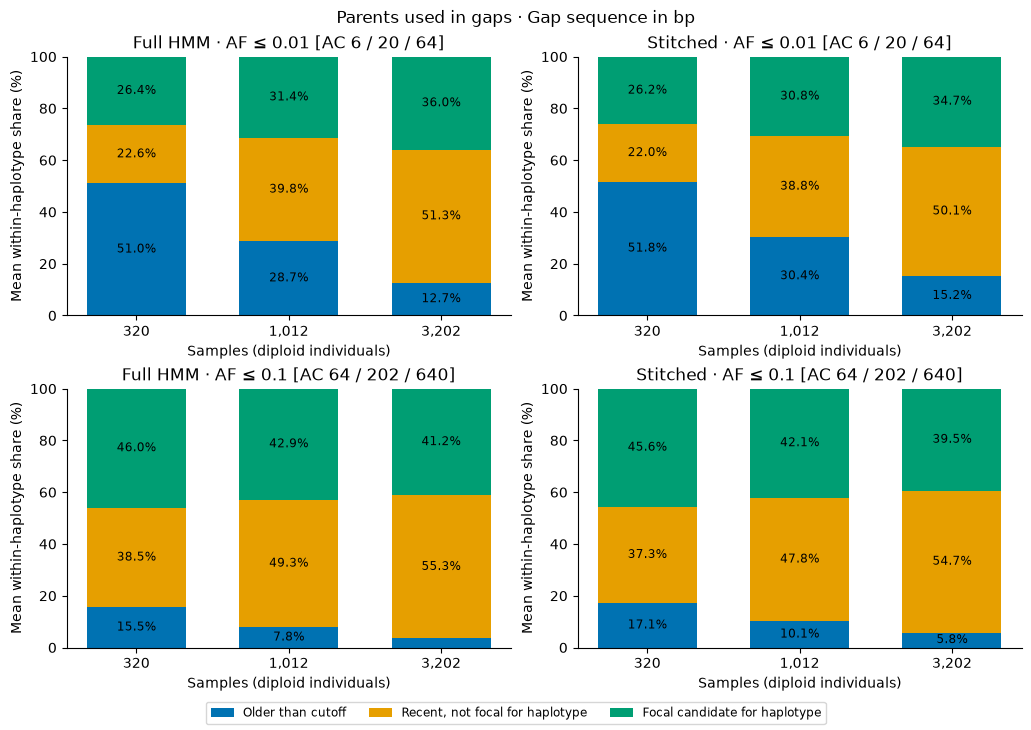

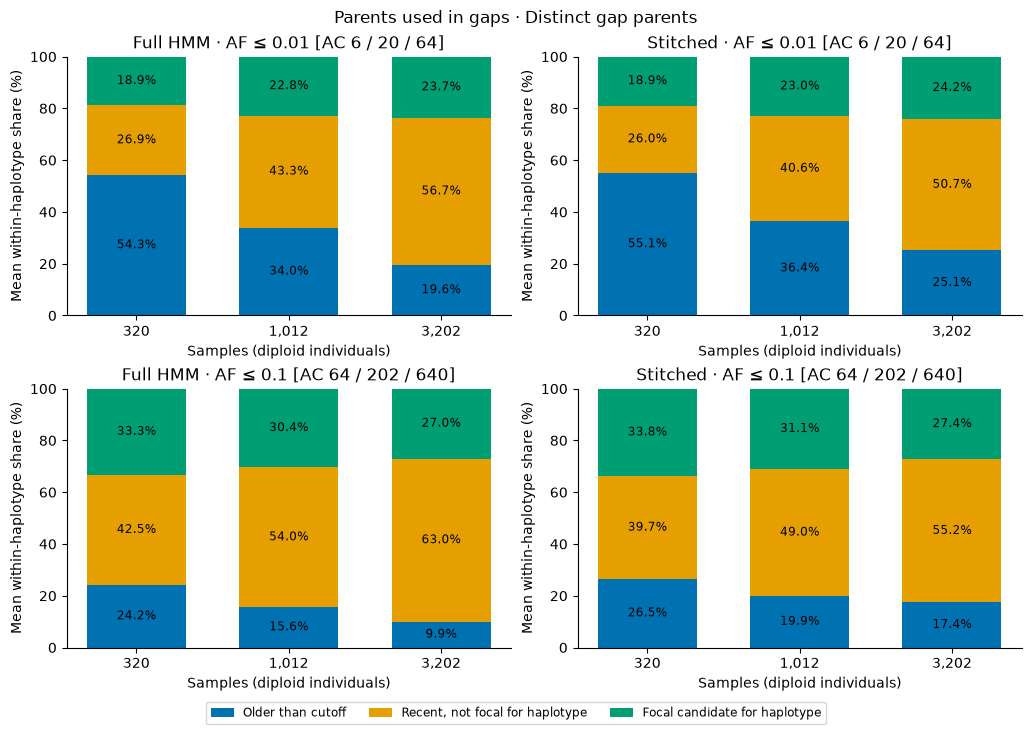

In [13]:
if __name__ == "__main__":
    gap_parents = nb_utils.gap_parent_composition(config)
    columns = [
        "num_samples",
        "method",
        "af_cutoff",
        "category",
        "span_bp_percentage_mean",
        "distinct_parents_percentage_mean",
    ]
    ipython_display.display(gap_parents[columns].round(2))
    for weight in {
        "span_bp": "Gap sequence in bp",
        "distinct_parents": "Distinct gap parents",
    }:
        nb_plot.save_cohort_figure(
            plot_data,
            nb_plot.plot_gap_parents(
                plot_data,
                gap_parents,
                weight,
                bar_width=0.65,
                gap_parent_categories={
                    "older": {"label": "Older than cutoff", "color": "#0072B2"},
                    "recent_nonfocal": {
                        "label": "Recent, not focal for haplotype",
                        "color": "#E69F00",
                    },
                    "focal": {
                        "label": "Focal candidate for haplotype",
                        "color": "#009E73",
                    },
                },
                gap_parent_label_minimum_percentage=5,
                gap_parent_weightings={
                    "span_bp": "Gap sequence in bp",
                    "distinct_parents": "Distinct gap parents",
                },
                method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
                panel_height=3.6,
                panel_width=5.1,
            ),
            f"gap_parents_{weight}",
            export_dpi=180,
        )

## Direct ultimate-root to sample edges

These are raw copying edges from the ultimate ancestor (the child of the
vestigial root) directly to sample haplotypes, before root splitting or dating.
Count each edge once if it overlaps the common archived analysis extent;
its span is the number of observed base pairs, excluding chromosome flanks.
Counts and summed spans are divided by the cohort's haplotype count.

Each AF uses its own focal mask for **both** Full HMM and stitched paths.
An edge is **at a seam** if it overlaps a gap and contains an internal
focal/gap boundary, including either edge endpoint. An edge in a gap with
no such boundary is **gap interior**. Remaining edges are **focal only**.
Chromosome/domain ends are not seams. Edges spanning multiple regions are
counted once with seam classification taking precedence.

The difference panels subtract Full HMM from stitched within each category;
these are signed aggregate differences, not a pairing of individual edges.
Positive and negative contributions are stacked separately, with a diamond
marking the net difference. Moving an edge between categories can therefore
create opposite contributions even without changing the total edge count.

Histograms use common logarithmic bins over the **complete** observed span
range. Stitched bars are stacked by location; Full HMM is the outline. Both
axes are logarithmic, and counts are edges per haplotype per bin.

Root/sample edges: tgp_chr20p_n320


Root/sample edges: tgp_chr20p_n1012


Root/sample edges: tgp_chr20p_n3202


,num_samples,af_cutoff,method,category,edge_count,span_bp,edge_count_per_haplotype,span_kb_per_haplotype
0,320,0.01,full_hmm,seam,1852,1099061.0,2.894,1.717
1,320,0.01,full_hmm,gap_interior,8466,5208708.0,13.228,8.139
2,320,0.01,full_hmm,focal,10,3864.0,0.016,0.006
3,320,0.01,greedy,seam,5561,1043128.0,8.689,1.630
4,320,0.01,greedy,gap_interior,8465,5205957.0,13.227,8.134
5,320,0.01,greedy,focal,0,0.0,0.000,0.000
6,320,0.10,full_hmm,seam,3747,2191941.0,5.855,3.425
7,320,0.10,full_hmm,gap_interior,6517,4074116.0,10.183,6.366
8,320,0.10,full_hmm,focal,64,45576.0,0.100,0.071
9,320,0.10,greedy,seam,9663,1903241.0,15.098,2.974


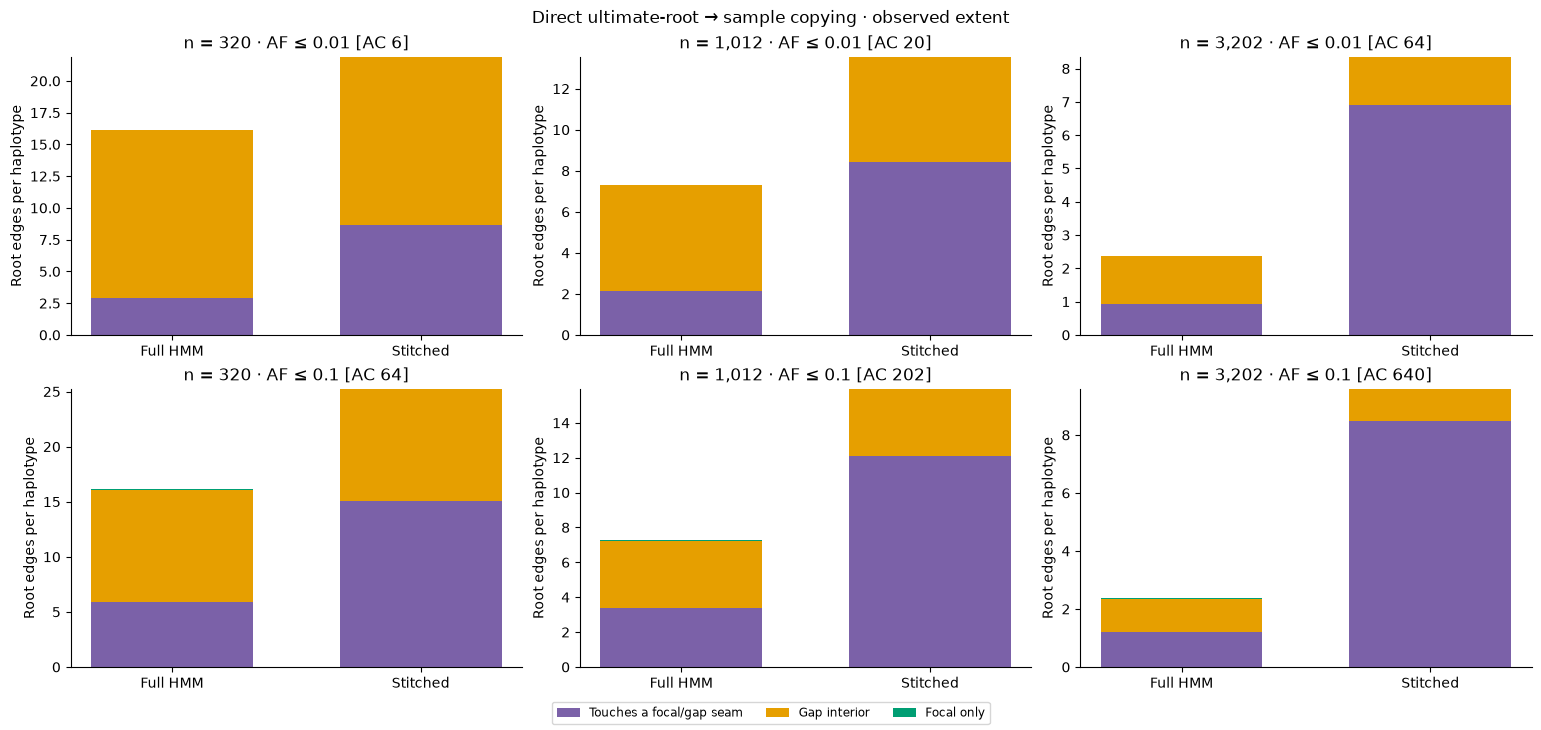

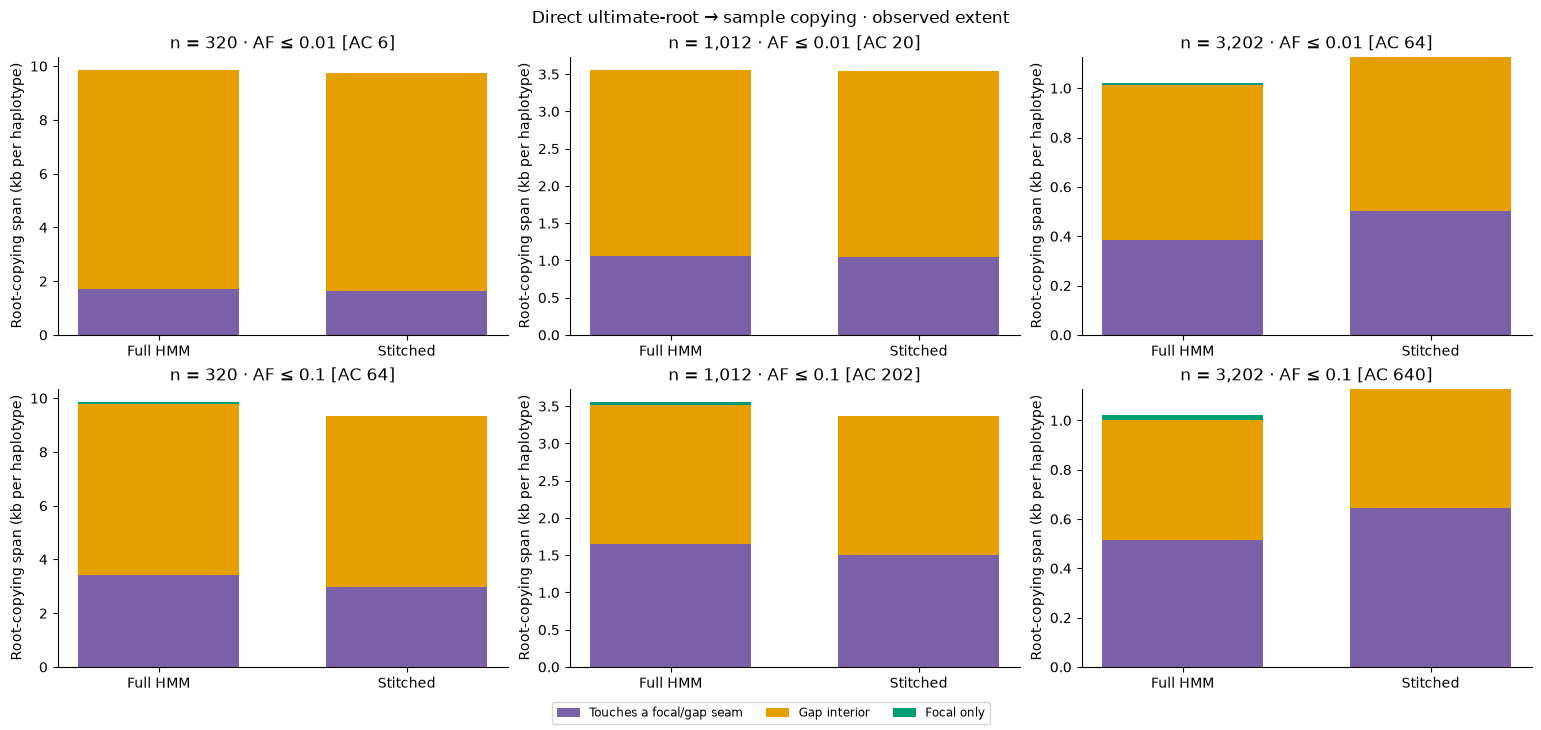

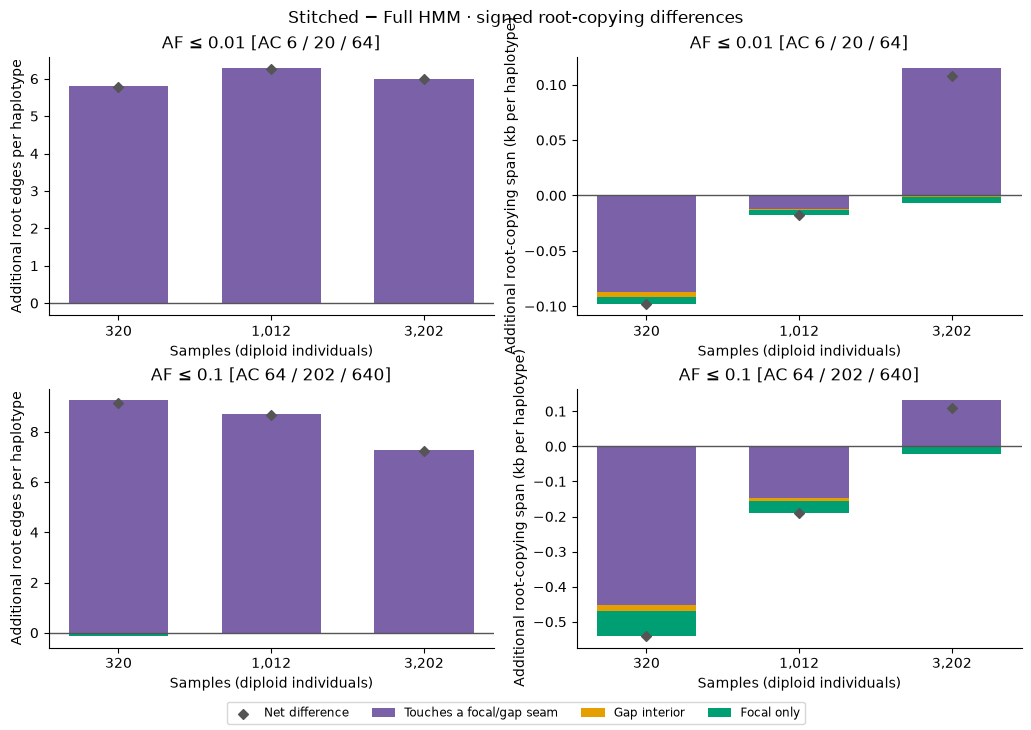

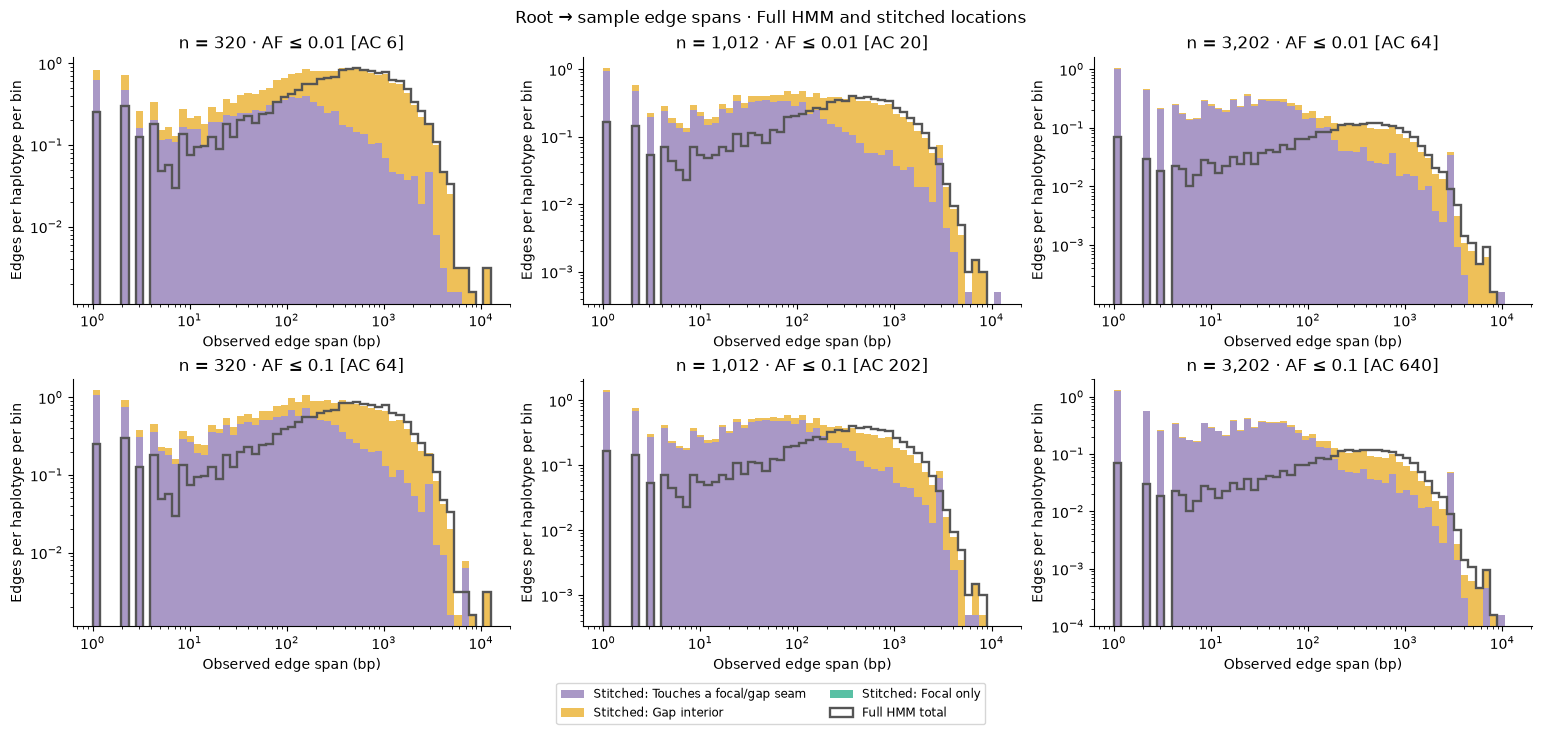

In [14]:
if __name__ == "__main__":
    root_edges = nb_utils.root_edge_summary(config)
    columns = [
        "num_samples",
        "af_cutoff",
        "method",
        "category",
        "edge_count",
        "span_bp",
        "edge_count_per_haplotype",
        "span_kb_per_haplotype",
    ]
    ipython_display.display(root_edges[columns].round(3))
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_edge_totals(
            plot_data,
            root_edges,
            "edge_count_per_haplotype",
            "Root edges per haplotype",
            bar_width=0.65,
            cohort_labels={},
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
        ),
        "root_edges_counts",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_edge_totals(
            plot_data,
            root_edges,
            "span_kb_per_haplotype",
            "Root-copying span (kb per haplotype)",
            bar_width=0.65,
            cohort_labels={},
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
        ),
        "root_edges_spans",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_edge_differences(
            plot_data,
            root_edges,
            bar_width=0.65,
            cohort_labels={},
            full_color="#555555",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
        ),
        "root_edges_additional",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_edge_spans(
            plot_data,
            cohort_labels={},
            full_color="#555555",
            line_width=1.7,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
            root_edge_histogram_alpha=0.65,
            root_edge_histogram_bins=55,
        ),
        "root_edges_span_histograms",
        export_dpi=180,
    )

## Saved tree counts and mutation dating

The following step checks that diagnostic and timed outputs have identical
copying paths and mutations, then records raw edge/tree counts. It computes
no ARF, TPR or other ARG metrics. Percentage changes use the raw Full HMM
counts, including retained reference ancestry.

Dating follows pt6/pt7: post-process saved trees, restrict to the common
archived extent, preprocess disjoint nodes and run variational-gamma tsdate.
**No variants are restored and no genotype stores are opened.** Mutation
rates are configured as 2.35 × 10⁻⁸ for the simulations and 1.29 × 10⁻⁸ for
1kgp, per bp per generation. Independent trees run in worker processes and
their dated outputs are cached.

Dated tgp_chr20p_n320_full_hmm (1/9)


Dated tgp_chr20p_n320_af_0.1_kb_150 (2/9)


Dated tgp_chr20p_n320_af_0.01_kb_150 (3/9)


Dated tgp_chr20p_n1012_af_0.1_kb_150 (4/9)


Dated tgp_chr20p_n3202_full_hmm (5/9)


Dated tgp_chr20p_n1012_full_hmm (6/9)


Dated tgp_chr20p_n1012_af_0.01_kb_150 (7/9)


Dated tgp_chr20p_n3202_af_0.01_kb_150 (8/9)


Dated tgp_chr20p_n3202_af_0.1_kb_150 (9/9)


,dataset,method,af_cutoff,raw_sites,dated_sites,num_edges,num_trees,benchmark_paths_identical
0,tgp_chr20p_n1012,full_hmm,NaN,342008,342007,2521881,249029,True
1,tgp_chr20p_n1012,greedy,0.01,342008,342007,2543258,250657,True
2,tgp_chr20p_n1012,greedy,0.10,342008,342007,2592446,250375,True
3,tgp_chr20p_n320,full_hmm,NaN,222876,222875,1181447,155006,True
4,tgp_chr20p_n320,greedy,0.01,222876,222875,1184513,155686,True
5,tgp_chr20p_n320,greedy,0.10,222876,222875,1197577,155992,True
6,tgp_chr20p_n3202,full_hmm,NaN,580909,580908,5745032,414142,True
7,tgp_chr20p_n3202,greedy,0.01,580909,580908,5852426,418736,True
8,tgp_chr20p_n3202,greedy,0.10,580909,580908,6009770,417561,True


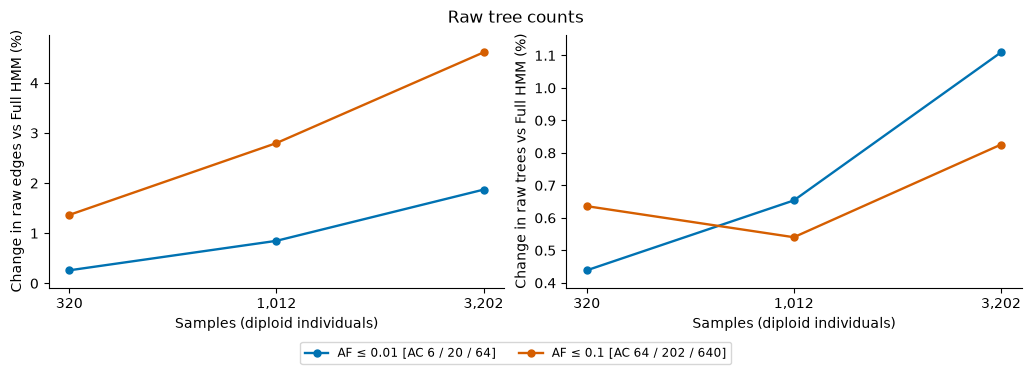

In [15]:
if __name__ == "__main__":
    dated = nb_utils.perf_scaling_date_all(config)
    ipython_display.display(
        dated[
            [
                "dataset",
                "method",
                "af_cutoff",
                "raw_sites",
                "dated_sites",
                "num_edges",
                "num_trees",
                "benchmark_paths_identical",
            ]
        ]
    )
    metrics = {
        "edges_change_percentage": "Change in raw edges vs Full HMM (%)",
        "trees_change_percentage": "Change in raw trees vs Full HMM (%)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            dated,
            metrics,
            "Raw tree counts",
            zoom=True,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "raw_tree_counts",
        export_dpi=180,
    )

## Mutation ages: association and calibration

Posterior **mutation means** (`mn`) are compared with simulated event times
where truth exists, and with Full HMM posterior means. 1kgp has no known true
ages; Full HMM is a comparison method, not truth.

For each cohort, use one common variant intersection across Full HMM, both
stitched runs and, for simulations, truth. Match position and ancestral/derived
states; exclude recurrent/back-mutation sites and nonfinite ages. All methods,
reference comparisons and frequency bins use that same cohort intersection.
The cached tables include its retention relative to each candidate set.

Pearson r uses untransformed ages in generations. Median absolute error
supplements association with a calibration measure. DAF is fixed from Full
HMM for every method; it is distinct from the AF cutoff used to select focal
ancestors. Bin boundaries enter the upper bin. Empty or constant-age bins
have undefined correlation and remain blank in the plots.

Mutation-age comparison complete: tgp_chr20p_n320


Mutation-age comparison complete: tgp_chr20p_n1012


Mutation-age comparison complete: tgp_chr20p_n3202


frequency_bin,0.01 ≤ DAF < 0.5,DAF < 0.01,DAF ≥ 0.5,all
dataset,,,,
tgp_chr20p_n1012,100772,193006,48229,342007
tgp_chr20p_n320,98474,83493,40908,222875
tgp_chr20p_n3202,100457,427252,53199,580908


,dataset,method,af_cutoff,finite_single_mutation_sites,common_mutations,retained_percentage
0,tgp_chr20p_n1012,full_hmm,NaN,342007,342007,100.0
1,tgp_chr20p_n1012,greedy,0.01,342007,342007,100.0
2,tgp_chr20p_n1012,greedy,0.10,342007,342007,100.0
3,tgp_chr20p_n3202,full_hmm,NaN,580908,580908,100.0
4,tgp_chr20p_n3202,greedy,0.01,580908,580908,100.0
5,tgp_chr20p_n3202,greedy,0.10,580908,580908,100.0
6,tgp_chr20p_n320,full_hmm,NaN,222875,222875,100.0
7,tgp_chr20p_n320,greedy,0.01,222875,222875,100.0
8,tgp_chr20p_n320,greedy,0.10,222875,222875,100.0


,dataset,num_samples,method,af_cutoff,reference_method,frequency_bin,matched_mutations,pearson_r,mean_error_generations,median_absolute_error_generations,mean_estimated_age,mean_reference_age
0,tgp_chr20p_n320,320,greedy,0.01,full_hmm,all,222875,0.9480,181.7950,96.8202,50358.5704,50176.7754
4,tgp_chr20p_n320,320,greedy,0.10,full_hmm,all,222875,0.9187,1470.9106,216.9376,51647.6859,50176.7754
8,tgp_chr20p_n1012,1012,greedy,0.01,full_hmm,all,342007,0.9327,1093.4766,75.2844,45368.1966,44274.7200
12,tgp_chr20p_n1012,1012,greedy,0.10,full_hmm,all,342007,0.9184,2497.3303,175.8492,46772.0503,44274.7200
16,tgp_chr20p_n3202,3202,greedy,0.01,full_hmm,all,580908,0.9062,1014.1847,41.2494,30510.4116,29496.2269
20,tgp_chr20p_n3202,3202,greedy,0.10,full_hmm,all,580908,0.8957,1827.0042,82.8053,31323.2311,29496.2269


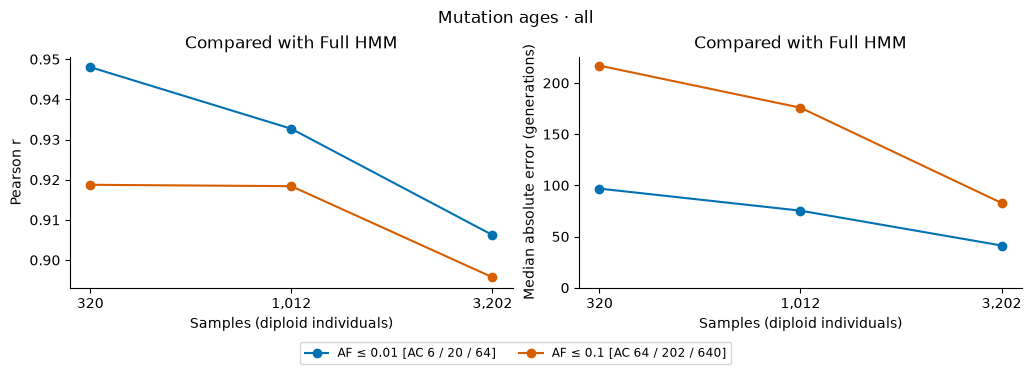

In [16]:
if __name__ == "__main__":
    ages = nb_utils.perf_scaling_mutation_correlations(config, dated)
    checks = ages.groupby(["dataset", "frequency_bin"]).matched_mutations.agg(
        ["min", "max"]
    )
    assert checks["min"].eq(checks["max"]).all()
    ipython_display.display(
        checks["min"].rename("matched_mutations").unstack("frequency_bin")
    )
    retention_paths = sorted(
        (config["cache_dir"] / "age_pairs").glob("*_retention.csv")
    )
    retention = pd.concat(
        [pd.read_csv(path) for path in retention_paths], ignore_index=True
    )
    ipython_display.display(retention.round(2))
    ipython_display.display(ages.loc[ages.frequency_bin.eq("all")].round(4))
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_age_correlations(
            plot_data,
            ages,
            cohort_labels={},
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "mutation_age_correlations",
        export_dpi=180,
    )

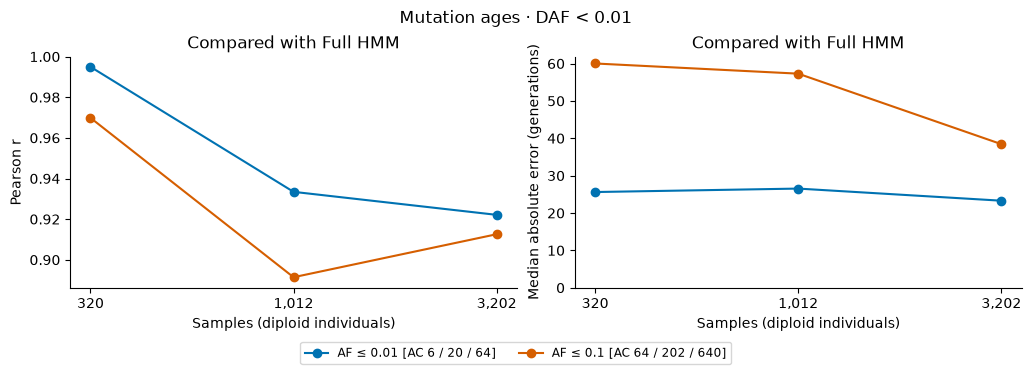

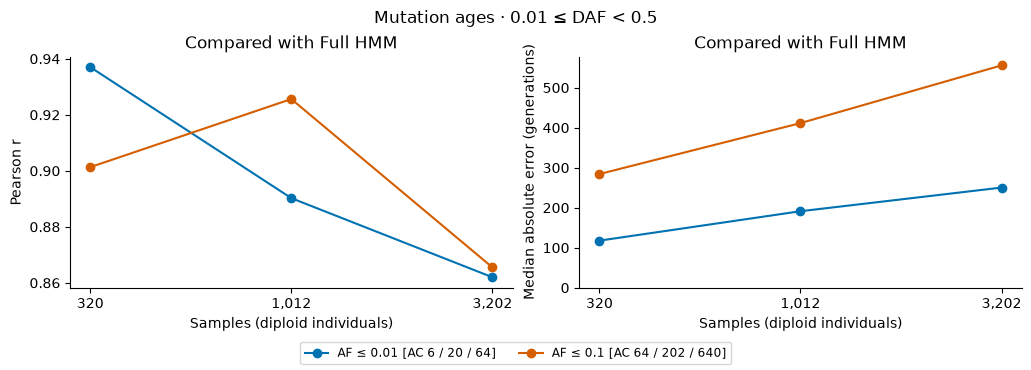

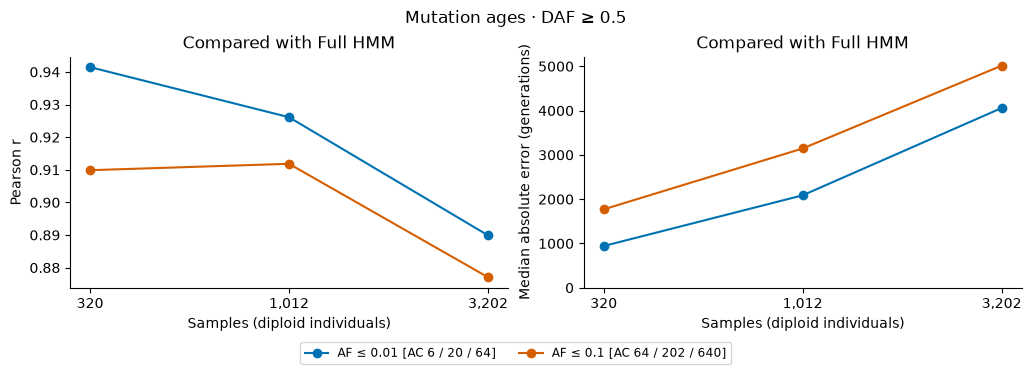

In [17]:
if __name__ == "__main__":
    for index, label in enumerate(config["frequency_bins"]["labels"]):
        nb_plot.save_cohort_figure(
            plot_data,
            nb_plot.plot_age_correlations(
                plot_data,
                ages,
                label,
                cohort_labels={},
                cutoff_colors=["#0072B2", "#D55E00"],
                full_color="#555555",
                line_width=1.7,
                marker="o",
                marker_size=5,
                method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
                method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
                panel_height=3.6,
                panel_width=5.1,
                real_data_marker="o",
                sample_tick_alignments={
                    "tgp_chr20p_n3202": "right",
                    "out_of_africa_n5000_28_1mbp_error": "left",
                },
                sample_tick_rotation=0,
            ),
            f"mutation_age_daf_{index}",
            export_dpi=180,
        )

## Paired mutation ages

Hexagons show counts with one shared logarithmic colour scale. The dashed
line is equality. Display bounds omit ages below one generation and use a
shared upper quantile; correlations and errors above use all matched ages,
including display tails. The annotated N is the complete common intersection.

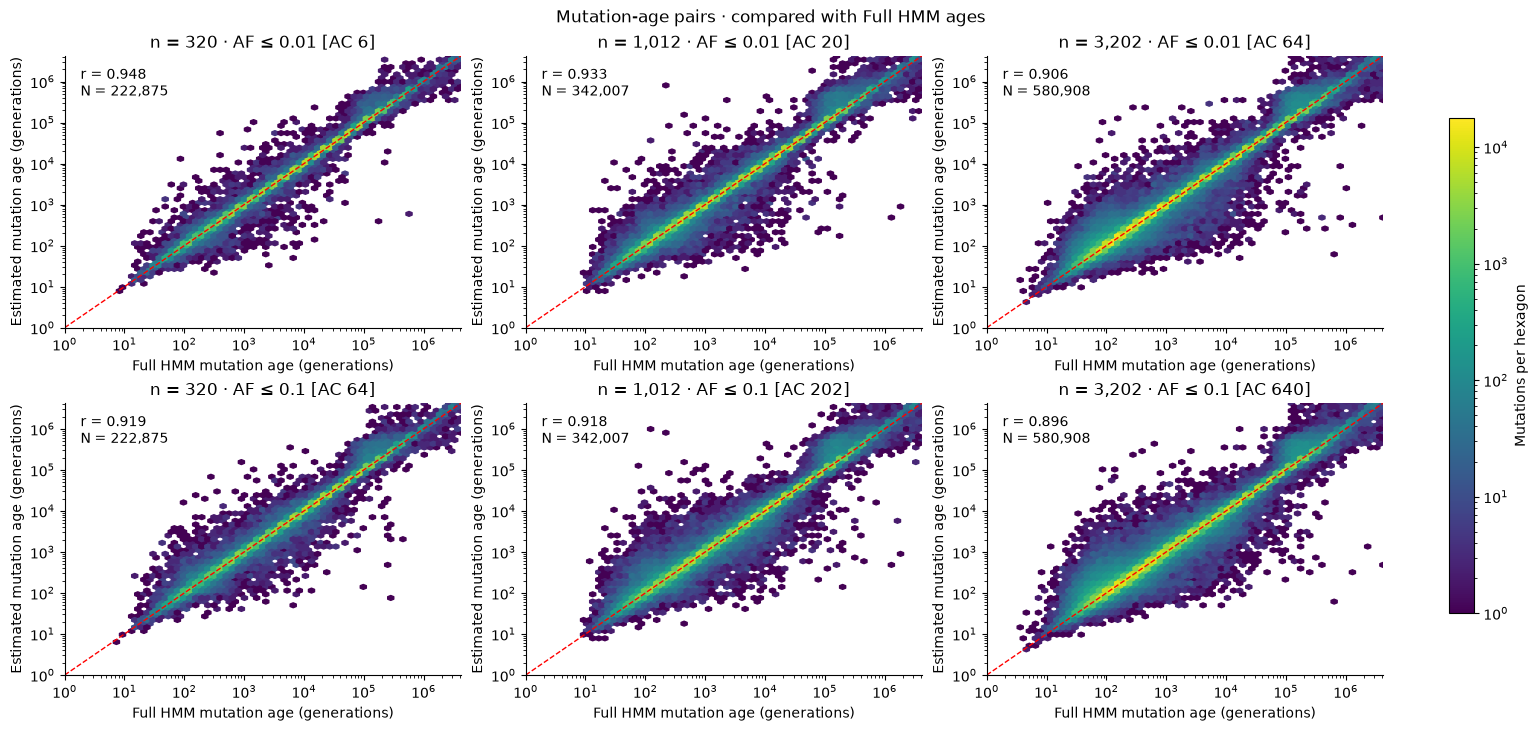

In [18]:
if __name__ == "__main__":
    if cohorts.has_truth.all():
        nb_plot.save_cohort_figure(
            plot_data,
            nb_plot.plot_age_density(
                plot_data,
                ages,
                "truth",
                age_hexbin_gridsize=65,
                age_maximum_quantile=0.999,
                age_minimum=1,
                cohort_labels={},
                method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
                method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
                panel_height=3.6,
                panel_width=5.1,
            ),
            "mutation_ages_vs_truth",
            export_dpi=180,
        )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_age_density(
            plot_data,
            ages,
            "full_hmm",
            age_hexbin_gridsize=65,
            age_maximum_quantile=0.999,
            age_minimum=1,
            cohort_labels={},
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=5.1,
        ),
        "mutation_ages_vs_full_hmm",
        export_dpi=180,
    )